<div style="font-family:Segoe UI,Calibri,sans-serif">
<div style="font-size:12px;letter-spacing:2px;color:#5B6770"></div>
<div style="font-size:12px;letter-spacing:1px;color:#2A78D6;font-weight:600">CS-320 &nbsp;&middot;&nbsp; ARTIFICIAL NEURAL NETWORKS &amp; DEEP LEARNING &nbsp;&middot;&nbsp; BSAI</div>
<div style="font-size:26px;font-weight:700;color:#14375E;margin-top:6px">Lab 5 &mdash; Gradient Descent: Batch, Stochastic and Mini-Batch</div>
<div style="font-size:14px;color:#4A4A4A;margin-top:4px">3 hours &nbsp;&middot;&nbsp; CLO 2, CLO 4</div>
</div>

---

 &nbsp; **Lab Engineer:** Ms Areeba Rameen &nbsp;|&nbsp; **Student name / CMS ID:** Muhammad Sikandar Hussain 502808

### What this lab is for

Every weight update you will write from here through the end of the course follows the same
three-step recipe: compute the loss, compute its gradient, and move the parameters a small
step in the direction that makes the loss smaller. Lab 4 built the first two ingredients —
losses and their gradients. This lab builds the third and final one: the update rule itself,
known as **gradient descent**.

Picture it concretely: you are standing somewhere on a hilly surface, blindfolded, and the
only thing you know is which direction the ground slopes downward right where you are
standing. Gradient descent is the strategy of always taking a small step in that downhill
direction, and repeating it until the ground stops sloping.

The interesting part is *how many different ways* there are to do this: do you look at the
whole dataset before taking a step, or just one example, or something in between? And how
big should each step be? You will implement three variants — **batch**, **stochastic**, and
**mini-batch** gradient descent — on the same small dataset, and watch directly in a plot
what changes between them.

**Submission.** Restart the kernel, run everything top to bottom, save, and rename to
`Lab5_<yourCMSID>.ipynb` before uploading to LMS.


## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(1)
print("ready")


ready


## Task 1 &mdash; Descending a simple bowl: building the intuition

> **Concept.** Before touching any real data, it helps to see gradient descent on the
> simplest possible loss: a one-dimensional bowl, `L(w) = (w - 3)**2`. This loss has exactly
> one lowest point, at `w = 3`. To the right of 3 the slope is positive (the curve rises as
> `w` increases); to the left of 3 the slope is negative.
>
> The update rule is simply:
>
> `w_new = w_old - lr * slope_at(w_old)`
>
> In words: look at the slope under your feet, then move a small step in the *opposite*
> direction of that slope — because the slope points uphill, and you want to go downhill.
> `lr` (the **learning rate**) is a small positive number that controls how big that step is.

**Task 1.1.** Implement `loss(w) = (w - 3)**2` and `grad(w) = 2 * (w - 3)`.

**Task 1.2.** Starting at `w = 0` with `lr = 0.1`, work out five update steps **by hand on
paper** first, writing down `w` after each step. Then write a short loop in code that
performs the same five updates, printing `w` each time, and confirm it matches your
hand-worked numbers.

**Task 1.3.** Plot `loss(w)` over `w` in `[-2, 8]`, and mark your five `w` values from Task
1.2 as points on the curve, so the descent is visible.


step 0: w = 0.00000
step 1: w = 0.60000
step 2: w = 1.08000
step 3: w = 1.46400
step 4: w = 1.77120
step 5: w = 2.01696


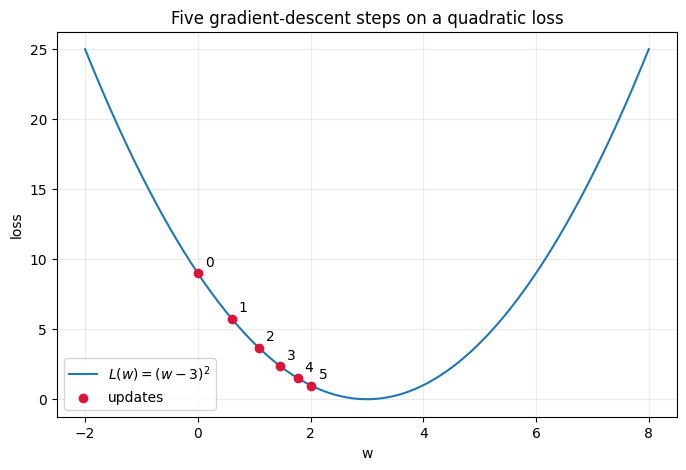

lr=0.5 trace: [0.0, 3.0, 3.0, 3.0, 3.0, 3.0]


In [2]:
def loss(w):
    """One-dimensional quadratic loss with its minimum at w = 3."""
    return (w - 3) ** 2

def grad(w):
    """Derivative of loss(w) = (w - 3)^2."""
    return 2 * (w - 3)

# Task 1.2 - hand-worked trace:
# w0 = 0.00000
# w1 = 0 - 0.1(-6)       = 0.60000
# w2 = 0.6 - 0.1(-4.8)   = 1.08000
# w3 = 1.08 - 0.1(-3.84) = 1.46400
# w4 = 1.464 - 0.1(-3.072) = 1.77120
# w5 = 1.7712 - 0.1(-2.4576) = 2.01696

w = 0.0
lr = 0.1
w_trace = [w]
print(f"step 0: w = {w:.5f}")
for step in range(1, 6):
    w = w - lr * grad(w)
    w_trace.append(w)
    print(f"step {step}: w = {w:.5f}")

# Task 1.3 - show the loss bowl and the five updates (plus the starting point).
w_grid = np.linspace(-2, 8, 400)
plt.figure(figsize=(8, 5))
plt.plot(w_grid, loss(w_grid), label=r"$L(w)=(w-3)^2$")
plt.scatter(w_trace, loss(np.array(w_trace)), color="crimson", zorder=3, label="updates")
for step, w_value in enumerate(w_trace):
    plt.annotate(str(step), (w_value, loss(w_value)), xytext=(5, 5),
                 textcoords="offset points")
plt.xlabel("w"); plt.ylabel("loss")
plt.title("Five gradient-descent steps on a quadratic loss")
plt.grid(alpha=0.25); plt.legend(); plt.show()

# Task 1 answers:
# Q1: The step magnitude shrinks as w approaches 3. Since grad(w)=2(w-3), its absolute
#     value approaches zero, and |w_new-w_old| = lr*|grad(w)| therefore also approaches 0.
# Q2: With lr=0.5, the first update is w=0-0.5(-6)=3. The gradient is then zero, so all
#     remaining updates stay at 3. It reaches the minimum in one step, faster than lr=0.1.
w_fast = 0.0
fast_trace = [w_fast]
for _ in range(5):
    w_fast -= 0.5 * grad(w_fast)
    fast_trace.append(w_fast)
print("lr=0.5 trace:", fast_trace)


## Task 2 &mdash; Batch gradient descent on linear regression

> **Concept.** Real models usually have more than one parameter, and the loss is computed
> over many data points. **Batch gradient descent** extends Task 1's idea directly: at every
> step, look at the *entire* dataset, compute the average loss and its gradient over all of
> it, and take one step. It is called "batch" because the whole dataset is used as a single
> batch, every single time.
>
> For a straight-line model `y_pred = w*x + b` trained with mean squared error, the
> gradients are given directly below — this is the same MSE gradient from Lab 4, just
> written for two parameters instead of one, so there is no need to re-derive it:
>
> `dL/dw = mean( 2 * (y_pred - y_true) * x )`
>
> `dL/db = mean( 2 * (y_pred - y_true) )`

Run the cell below to build a small linear dataset you will reuse for the rest of this lab.

**Task 2.1.** Implement `predict(x, w, b)`, `mse_loss(y_true, y_pred)`, and
`mse_grad(x, y_true, y_pred)` returning `(dw, db)` using the formulas above.

**Task 2.2.** Implement `batch_gradient_descent(x, y, lr, epochs)`: start with `w = 0`,
`b = 0`; on every epoch use the *full* `x` and `y` to compute predictions, the loss, and the
gradients, then update `w` and `b` once. Store the loss at every epoch in a list, and return
`w`, `b`, and that list.

**Task 2.3.** Run with `lr = 0.01`, `epochs = 100`. Plot the loss list against the epoch
number. Report the final `w` and `b`, and compare them to the true values (3 and 5) used to
generate the data.


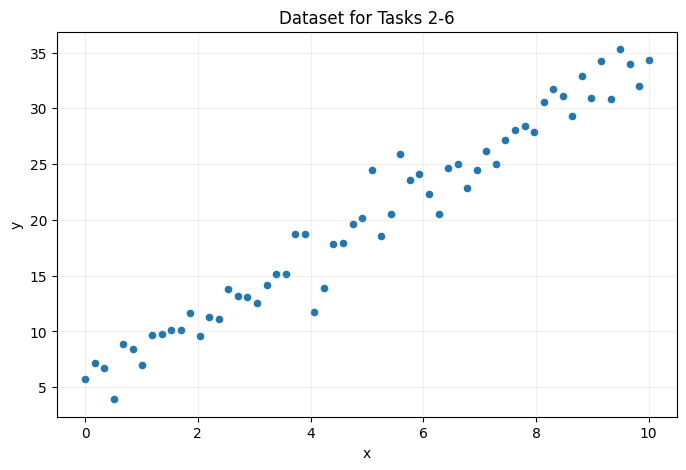

learned w = 3.3677, b = 2.3653
true generating values: w = 3, b = 5
final batch loss = 4.9696


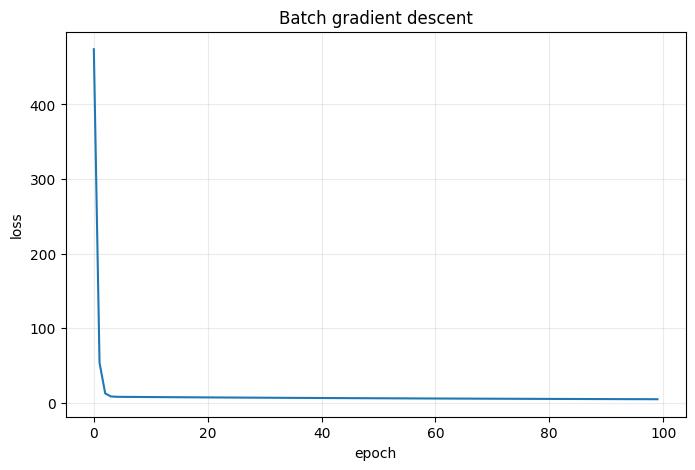

In [3]:
n = 60
x = np.linspace(0, 10, n)
y = 3 * x + 5 + rng.normal(0, 2, n)      # true relationship: y = 3x + 5, plus noise

plt.figure(figsize=(8, 5))
plt.scatter(x, y, s=20)
plt.xlabel("x"); plt.ylabel("y"); plt.title("Dataset for Tasks 2-6")
plt.grid(alpha=0.2); plt.show()

def predict(x, w, b):
    return w * np.asarray(x) + b

def mse_loss(y_true, y_pred):
    return np.mean((np.asarray(y_pred) - np.asarray(y_true)) ** 2)

def mse_grad(x, y_true, y_pred):
    x = np.asarray(x)
    error = np.asarray(y_pred) - np.asarray(y_true)
    dw = np.mean(2 * error * x)
    db = np.mean(2 * error)
    return dw, db

def batch_gradient_descent(x, y, lr, epochs):
    w, b = 0.0, 0.0
    losses = []
    for _ in range(epochs):
        y_pred = predict(x, w, b)
        losses.append(mse_loss(y, y_pred))
        dw, db = mse_grad(x, y, y_pred)
        w -= lr * dw
        b -= lr * db
    return w, b, losses

w_batch, b_batch, loss_batch = batch_gradient_descent(x, y, lr=0.01, epochs=100)
print(f"learned w = {w_batch:.4f}, b = {b_batch:.4f}")
print("true generating values: w = 3, b = 5")
print(f"final batch loss = {loss_batch[-1]:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(loss_batch)
plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Batch gradient descent")
plt.grid(alpha=0.25); plt.show()

# Task 2 answers:
# Q1: The loss falls smoothly because every update uses the same full set of 60 examples.
#     Averaging over all examples makes the gradient stable rather than sample-dependent.
#     After 100 epochs w is fairly near 3, while b is still below 5; the smooth decreasing
#     curve shows that more epochs are needed, not that training has failed.
# Q2: The gradient is computed once per epoch, so 100 epochs perform 100 computations
#     (and consequently 100 parameter updates).


## Task 3 &mdash; Stochastic gradient descent (SGD)

> **Concept.** Batch gradient descent is accurate, but recomputing a gradient over the
> entire dataset for every step gets expensive once a dataset is large. **Stochastic
> Gradient Descent (SGD)** goes to the opposite extreme: at every step, it picks just **one**
> example at random, computes the gradient using only that one example, and updates
> immediately. Each step is far cheaper, but also noisier — a single example is not always a
> reliable summary of "which way is downhill" for the whole dataset. One **epoch** of SGD
> means looping through every example once, one at a time, in a random (shuffled) order.

**Task 3.1.** Implement `stochastic_gradient_descent(x, y, lr, epochs)`. In each epoch:
shuffle the indices, then loop through the examples one at a time in that shuffled order,
computing the gradient from that single example only and updating `w` and `b` immediately
after each one. At the **end** of each epoch (after every example has been visited once),
compute and store the loss over the *whole* dataset, so it can be compared fairly with Task
2.

**Task 3.2.** Run with the same `lr` and `epochs` as Task 2. Plot this loss curve on the
same axes as Task 2's batch curve, with a legend.


learned w = 2.7791, b = 5.1993


final SGD loss = 3.8639


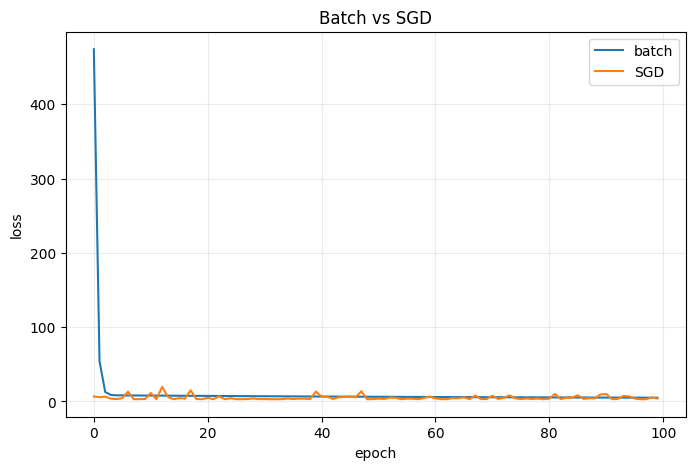

In [4]:
def stochastic_gradient_descent(x, y, lr, epochs):
    w, b = 0.0, 0.0
    losses = []
    n = len(x)
    for _ in range(epochs):
        for i in rng.permutation(n):
            y_pred_i = predict(x[i:i+1], w, b)
            dw, db = mse_grad(x[i:i+1], y[i:i+1], y_pred_i)
            w -= lr * dw
            b -= lr * db
        losses.append(mse_loss(y, predict(x, w, b)))
    return w, b, losses

w_sgd, b_sgd, loss_sgd = stochastic_gradient_descent(x, y, lr=0.01, epochs=100)
print(f"learned w = {w_sgd:.4f}, b = {b_sgd:.4f}")
print(f"final SGD loss = {loss_sgd[-1]:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(loss_batch, label="batch")
plt.plot(loss_sgd, label="SGD")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Batch vs SGD")
plt.grid(alpha=0.25); plt.legend(); plt.show()

# Task 3 answers:
# Q1: Batch is smoother. Its step averages all 60 examples, whereas each SGD step uses one
#     example, whose noise can point the update somewhat differently from the full gradient.
# Q2: Yes. Although SGD fluctuates more, its final loss is in the same low range as batch
#     gradient descent (the exact last value varies with the shuffle order).


## Task 4 &mdash; Mini-batch gradient descent

> **Concept.** Mini-batch gradient descent sits between the two extremes you have already
> implemented. Instead of the whole dataset (batch) or a single example (SGD), it uses a
> small group of examples — a **mini-batch**, commonly 8, 16 or 32 at a time — to compute
> each gradient step. This is the version used almost everywhere in practice, because it
> balances the stability of batch gradient descent against the speed of SGD. One epoch means:
> shuffle the data, split it into consecutive chunks of `batch_size` examples, and take one
> gradient step per chunk.

**Task 4.1.** Implement `mini_batch_gradient_descent(x, y, lr, epochs, batch_size)`. In each
epoch, shuffle the data, split it into chunks of `batch_size` examples, and take one
gradient step per chunk using only that chunk's examples. At the end of each epoch, compute
and store the loss over the whole dataset.

**Task 4.2.** Run with `batch_size = 8`, the same `lr` and `epochs` as Tasks 2 and 3. Plot
this loss curve together with the batch and SGD curves, all three on one axes with a
legend.


learned w = 2.9218, b = 5.0761
final mini-batch loss = 3.0140


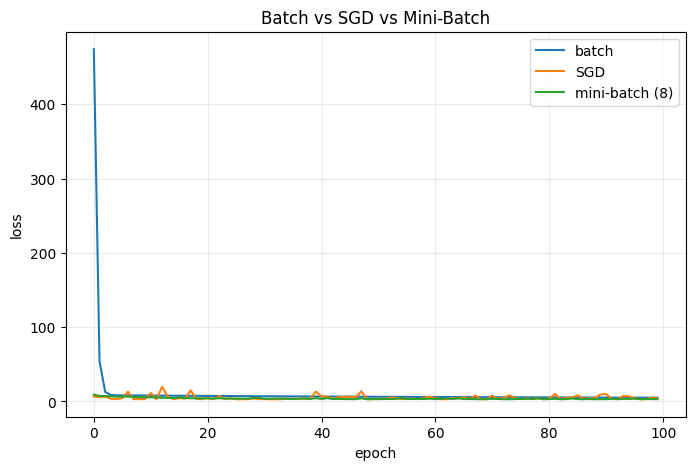

In [5]:
def mini_batch_gradient_descent(x, y, lr, epochs, batch_size):
    w, b = 0.0, 0.0
    losses = []
    n = len(x)
    for _ in range(epochs):
        indices = rng.permutation(n)
        for start in range(0, n, batch_size):
            batch_indices = indices[start:start + batch_size]
            x_batch, y_batch = x[batch_indices], y[batch_indices]
            y_pred_batch = predict(x_batch, w, b)
            dw, db = mse_grad(x_batch, y_batch, y_pred_batch)
            w -= lr * dw
            b -= lr * db
        losses.append(mse_loss(y, predict(x, w, b)))
    return w, b, losses

w_mb, b_mb, loss_mb = mini_batch_gradient_descent(x, y, lr=0.01, epochs=100, batch_size=8)
print(f"learned w = {w_mb:.4f}, b = {b_mb:.4f}")
print(f"final mini-batch loss = {loss_mb[-1]:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(loss_batch, label="batch")
plt.plot(loss_sgd, label="SGD")
plt.plot(loss_mb, label="mini-batch (8)")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Batch vs SGD vs Mini-Batch")
plt.grid(alpha=0.25); plt.legend(); plt.show()

# Task 4 answers:
# Q1: Mini-batch is the middle ground: normally less noisy than SGD but less perfectly
#     smooth than batch, because each update averages 8 examples rather than 1 or all 60.
# Q2: At batch_size=60 it becomes batch gradient descent: one stable update per epoch. At
#     batch_size=1 it becomes SGD: 60 noisy updates per epoch.


## Task 5 &mdash; Reading the three curves together

> **Concept.** With all three variants implemented, it is worth comparing them on a shared
> basis rather than only by eye. Two things matter: how low the loss ends up (accuracy of
> the result), and how many individual gradient computations each approach performed to get
> there (cost of the result). A "gradient computation" here means one pass over however many
> examples a single step used — one pass over the whole dataset counts as one; one pass over
> a single example also counts as one.

**Task 5.1.** Using your three runs from Tasks 2&ndash;4 (same `lr` and `epochs`
throughout), fill in the table below: the final loss value, the total number of parameter
updates performed over the whole run, and a one-word description of how noisy its curve
looked (e.g. smooth, moderate, noisy).

| Variant     | Final Loss | Total Updates | Curve Noise |
|-------------|-----------|----------------|-------------|
| Batch       |           |                |             |
| SGD         |           |                |             |
| Mini-Batch  |           |                |             |


In [6]:
# Task 5.1 - comparison table calculated from the three runs.
epochs = 100
batch_updates = epochs
sgd_updates = epochs * len(x)
mini_batch_updates = epochs * int(np.ceil(len(x) / 8))

rows = [
    ("Batch", loss_batch[-1], batch_updates, "smooth"),
    ("SGD", loss_sgd[-1], sgd_updates, "noisy"),
    ("Mini-batch (8)", loss_mb[-1], mini_batch_updates, "moderate"),
]
print(f"{'Variant':<16} {'Final loss':>12} {'Updates':>10} {'Curve':>10}")
print("-" * 52)
for name, final_loss, updates, noise in rows:
    print(f"{name:<16} {final_loss:>12.4f} {updates:>10} {noise:>10}")

# Task 5 answers:
# Q1: Mini-batch would usually reach a usable model fastest in wall-clock time. It updates
#     more often than full batch, uses vectorized chunks more efficiently than one-example
#     SGD, and its averaged gradient is stable enough to make useful progress.
# Q2: Batch is attractive for a small dataset, deterministic debugging, or when a stable
#     and directly interpretable loss trajectory matters. Its smoothness makes convergence,
#     learning-rate problems, and stopping decisions easier to diagnose.


Variant            Final loss    Updates      Curve
----------------------------------------------------
Batch                  4.9696        100     smooth
SGD                    3.8639       6000      noisy
Mini-batch (8)         3.0140        800   moderate


## Task 6 &mdash; The effect of learning rate on convergence

> **Concept.** The learning rate decides how big a step gradient descent takes in the
> downhill direction. Too small, and training creeps forward so slowly the loss barely moves
> in the epochs you allow it. Too large, and a single step can overshoot the minimum
> entirely — the loss may bounce back and forth, grow instead of shrink, or even overflow to
> `inf`/`nan`. Finding a learning rate that is "just right" is one of the most common
> practical tasks in training any model.

**Task 6.1.** Using `batch_gradient_descent()` from Task 2, run it separately with
`lr = 0.001, 0.01, 0.1, 1.0, 5.0`, for the same number of epochs each time. Plot all five
loss curves on one axes, with a legend naming each learning rate.

**Task 6.2.** From the plot, label each learning rate as one of: **too slow**, **good**, or
**diverging** (loss grows instead of shrinking, or becomes `inf`/`nan`). If a run produces
`inf`/`nan` values that make the plot hard to read, you may clip or omit those points — just
say so in a comment.


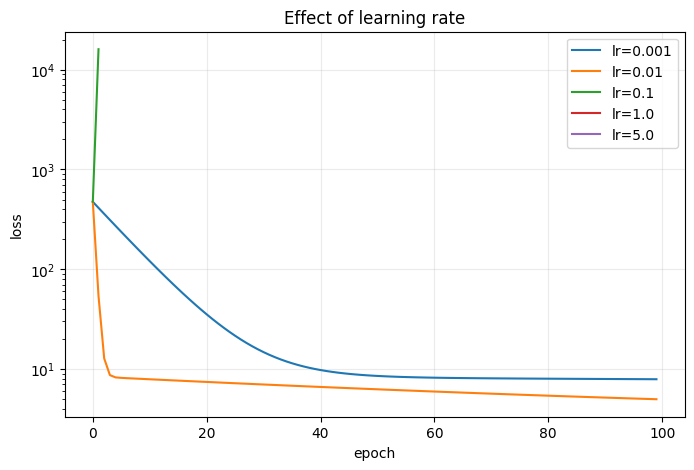

Learning-rate classifications:
lr=0.001: too slow   final w=3.604, b=0.7704, loss=7.884
lr=0.01 : good       final w=3.368, b=2.365, loss=4.97
lr=0.1  : diverging  final w=-2.801e+77, b=-4.197e+76, loss=7.992e+154
lr=1.0  : diverging  final w=-4.359e+183, b=-6.532e+182, loss=inf
lr=5.0  : diverging  final w=-1.113e+254, b=-1.667e+253, loss=inf


In [7]:
learning_rates = [0.001, 0.01, 0.1, 1.0, 5.0]
lr_results = {}

plt.figure(figsize=(8, 5))
for lr_try in learning_rates:
    with np.errstate(over="ignore", invalid="ignore"):
        w_lr, b_lr, loss_lr = batch_gradient_descent(x, y, lr=lr_try, epochs=100)
    lr_results[lr_try] = (w_lr, b_lr, loss_lr)
    loss_for_plot = np.asarray(loss_lr, dtype=float)
    # Omit non-finite points and clip huge values so the useful curves remain readable.
    loss_for_plot[~np.isfinite(loss_for_plot)] = np.nan
    loss_for_plot[loss_for_plot > 1e5] = np.nan
    plt.plot(loss_for_plot, label=f"lr={lr_try}")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Effect of learning rate")
plt.yscale("log")
plt.grid(alpha=0.25); plt.legend(); plt.show()

classifications = {
    0.001: "too slow",
    0.01: "good",
    0.1: "diverging",
    1.0: "diverging",
    5.0: "diverging",
}
print("Learning-rate classifications:")
for lr_try in learning_rates:
    w_lr, b_lr, losses = lr_results[lr_try]
    print(f"lr={lr_try:<5}: {classifications[lr_try]:<10} "
          f"final w={w_lr:.4g}, b={b_lr:.4g}, loss={losses[-1]:.4g}")

# Task 6 answers:
# Q1: lr=0.01 is the good rate. The slope gets close to 3 early, but the intercept converges
#     more slowly. It does not get both parameters within 0.5 of (3,5) during the plotted
#     100 epochs; continuing the same run reaches that tolerance at about epoch 390.
# Q2: Too large makes loss oscillate upward, explode, or become inf/nan. Too small remains
#     finite and usually decreases smoothly, but so slowly that the curve is still far above
#     its useful minimum after the available epochs.
# Q3: Start with two rates separated by a factor of ten (for example 0.001 and 0.01). Keep
#     the faster stable one, then bracket around it: lower the rate if loss explodes/oscillates,
#     or raise it if loss decreases smoothly but far too slowly.


---

### Before you submit

- [ ] Kernel &rarr; Restart & Run All, no errors.
- [ ] Every `TODO` and every `raise NotImplementedError` gone.
- [ ] Task 1's hand-worked trace and code trace agree.
- [ ] The batch / SGD / mini-batch loss curves are all plotted together in Task 4.
- [ ] The Task 5 comparison table is filled in.
- [ ] The five-learning-rate plot in Task 6 is produced and each rate is labelled.
- [ ] Written answers present as comments: 1 (Q1&ndash;Q2), 2 (Q1&ndash;Q2), 3 (Q1&ndash;Q2),
      4 (Q1&ndash;Q2), 5 (Q1&ndash;Q2), 6 (Q1&ndash;Q3)
- [ ] Renamed to `Lab5_<yourCMSID>.ipynb`.

### One thing to take away

You now have all three pieces needed to train a network: a loss, its gradient, and an update
rule that uses that gradient to improve the parameters step by step. The difference between
batch, stochastic and mini-batch gradient descent is purely a question of *how much data* to
look at before taking each step — everything else about the recipe stays the same. The next
labs reuse this update rule unchanged, applying it to networks with many more parameters than
the two you tuned here.
